In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
df = pd.read_csv("/content/Mall_Customers - Mall_Customers.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
df.shape

(200, 5)

In [ ]:
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


In [ ]:
# Select Annual Income and Spending Score as feature variables for clustering and
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
print("Features selected for clustering: Annual Income and Spending Score")

Features selected for clustering: Annual Income and Spending Score


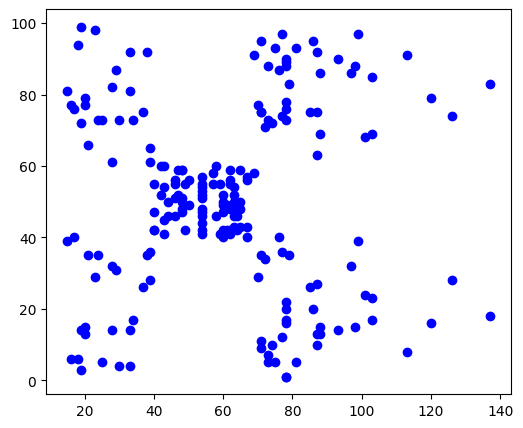

In [ ]:
# Visualize the original data points by plotting Annual Income against Spending Sc
plt.figure(figsize=(6,5))
plt.scatter(
X['Annual Income (k$)'],
X['Spending Score (1-100)'],
color='blue'
)

In [ ]:
# Apply StandardScaler to normalize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


In [ ]:
# Initialize the K-Means algorithm with 5 clusters and train it on the scaled feat
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X_scaled)
print("Model trained successfully")

Model trained successfully


In [ ]:
# Assign cluster labels to the original dataset and display the first 5 rows with
labels = kmeans.labels_
df['Cluster'] = labels
df[['Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']].head()

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


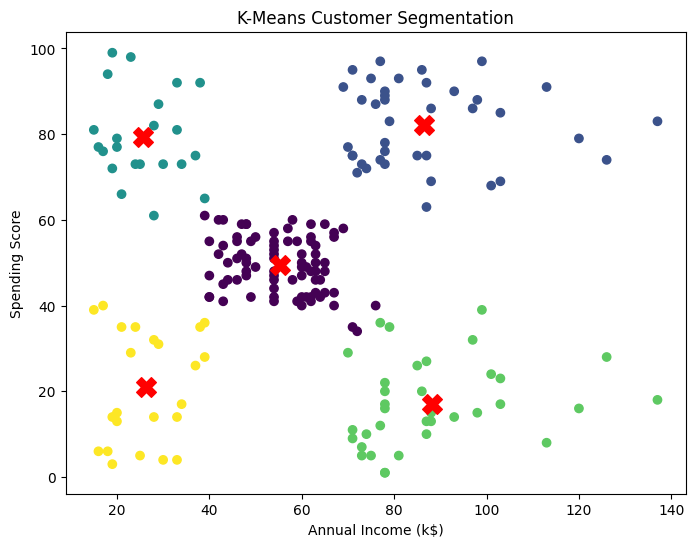

In [ ]:
# Visualize the clusters by plotting Annual Income against Spending Score, with co
plt.figure(figsize=(8,6))
plt.scatter(
X['Annual Income (k$)'],
X['Spending Score (1-100)'],
c=labels,
cmap='viridis'
)
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
centers[:,0],
centers[:,1],
c='red',
s=200,
marker='X'
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Segmentation")
plt.show()

In [ ]:
# Calculate and display model evaluation metrics: Silhouette Score, WCSS (Inertia),
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)
wcss = kmeans.inertia_
print("WCSS (Inertia):", wcss)
db_score = davies_bouldin_score(X_scaled, labels)
print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.5546571631111091
WCSS (Inertia): 65.56840815571681
Davies-Bouldin Index: 0.5722356162263352
